# **Architectural Inductive Bias and Robustness Under Distribution Shift**
**COMP 432 — Machine Learning | Winter 2026**

# **Abstract**

This project examines whether differences in robustness to distribution shift across neural network architectures are better explained by architectural inductive bias rather than by model capacity. Three architectures are compared: a Multi-Layer Perceptron (MLP), a Convolutional Neural Network (CNN), and a small ResNet-style model, all matched to approximately 100,000 trainable parameters. Each model is trained on clean Fashion-MNIST data and evaluated on systematically corrupted test sets that include Gaussian noise, Gaussian blur, and brightness shift at five severity levels. Performance is measured using classification accuracy, robustness degradation curves, robustness gap metrics, and invariance consistency scores.
The results show a notable reversal: although the MLP achieves the lowest clean accuracy (87.92%), it is the most robust architecture under all three corruption types. In contrast, the ResNet, which achieves the highest clean accuracy (91.57%), experiences the most severe degradation, dropping to 21% accuracy under heavy brightness shift. These findings suggest that while convolutional inductive bias helps improve performance on clean data, it may also introduce structural dependencies that make these architectures more brittle under distribution shift.



# **Introduction**

Neural networks have achieved strong performance on standard image classification benchmarks, but their robustness often deteriorates when test data differs from training data, a phenomenon known as distribution shift [1]. In real-world applications, images are frequently affected by corruptions such as sensor noise, camera blur, or lighting changes, so robustness is an essential property beyond clean accuracy.

Convolutional Neural Networks (CNNs) are widely used as the default architecture for image tasks because their inductive biases, local connectivity and weight sharing, align with the spatial structure of natural images [2]. Residual networks (ResNets) extend CNNs with skip connections that improve gradient flow and enable effective training of deeper architectures [3]. Both CNNs and ResNets consistently outperform fully connected networks on clean benchmarks, but it is less clear whether this advantage persists when distribution shift is introduced.


Prior work on robustness benchmarks, such as Hendrycks and Dietterich [1], has shown that neural networks are broadly vulnerable to common corruptions. However, these studies rarely control for model capacity when comparing architectures, which makes it difficult to isolate the effect of architecture itself. A network with more parameters may simply learn more generalizable features, regardless of its structural design.

This project addresses this gap through a controlled experiment on Fashion-MNIST [4], a standard image classification dataset of 28×28 grayscale clothing images. Parameter-matched MLP, CNN, and ResNet-style models are trained on clean data and evaluated under three corruption types at five severity levels. By holding capacity constant across architectures, the experiment aims to isolate the effect of architectural inductive bias on robustness to distribution shift.

The results reveal a counterintuitive pattern: the MLP, despite achieving lower clean accuracy, is more robust than the CNN and ResNet under all corruption types tested. This suggests that spatial inductive bias, while helpful on clean data, may introduce structural fragility under distribution shift.

# **Methodology**

This study compares three parameter-matched neural network architectures on Fashion-MNIST to isolate the effect of architectural inductive bias on robustness to distribution shift.

**Originality relative to prior work**: Prior robustness benchmarks, such as Hendrycks and Dietterich (2019), evaluate architectures without controlling for model capacity, which makes it difficult to separate the effect of architecture from the effect of having more parameters. This project instead holds capacity constant across all three models in order to isolate architectural inductive bias, a controlled experimental design not commonly applied in robustness studies at this scale.

**Preprocessing**: All images are normalized to the range [-1, 1] using mean = 0.5 and standard deviation = 0.5. The 60,000 training samples are split into 50,000 training and 10,000 validation examples using a fixed random seed (42) for reproducibility. The official 10,000 test samples are held out entirely until final evaluation, and no decisions are made based on test performance.

**Parameter matching**: All three models are designed to have approximately 100,000 trainable parameters (MLP: 109,386; CNN: 108,618; ResNet: 110,911), differing by at most 2.1%. This setup ensures that any observed robustness differences cannot be attributed to capacity differences. Parameter counts are explicitly verified before training.

**Training protocol**: All models use identical hyperparameters: Adam optimizer with a learning rate of 0.001, batch size 64, and a maximum of 30 epochs. Early stopping with patience 5 is applied based on validation loss, and the best model checkpoint is restored when early stopping is triggered. This choice is important because, without early stopping, the CNN and ResNet would have been evaluated in an overfit state (both began overfitting around epochs 10–12 in preliminary runs), which would have confounded the robustness comparison.

**Corruption protocol**: Three corruption types are applied exclusively to the test set at five severity levels (1 = mild, 5 = severe). The training data remains clean throughout, simulating real-world deployment where a model trained on clean data encounters corrupted inputs. Corruptions are implemented as parameterized PyTorch operations applied per batch at evaluation time.

**Best model — SmallResNet architecture:**

The ResNet-style model is the most architecturally complex of the three. It consists of a stem convolutional block, two residual blocks, and a fully connected classifier. The key feature is the skip connection in each residual block, which adds the block’s input directly to its output:

    output = F(x) + x

This structure allows gradients to flow directly through the skip path during backpropagation, helping to address the vanishing gradient problem. The second residual block uses stride = 2 to downsample spatial dimensions, and a 1×1 shortcut convolution is used to match channel dimensions before the residual addition.

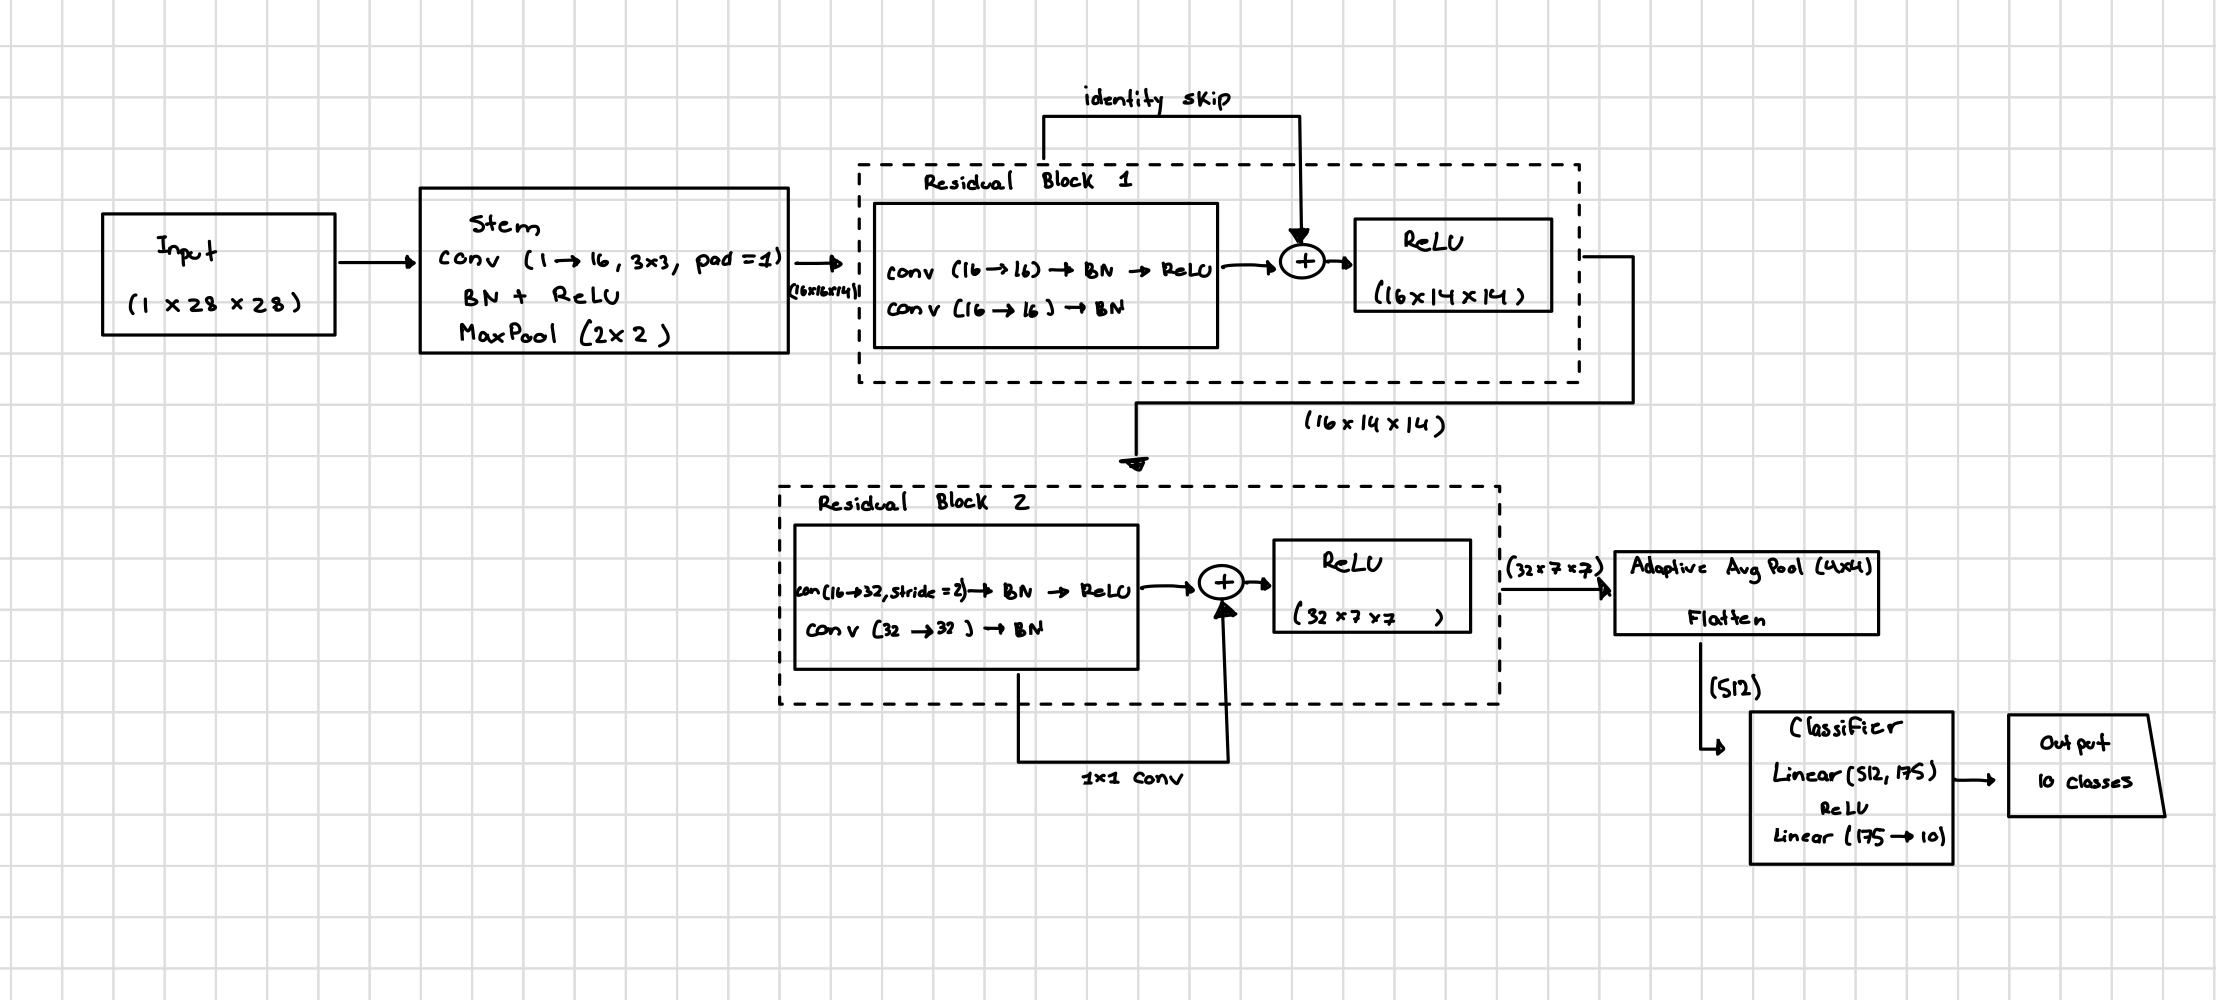

***Figure 1.** Diagram of SmallResNet Architecture*


# **Experimental Setup**

This experiment uses the [`Fashion-MNIST`](https://github.com/zalandoresearch/fashion-mnist) dataset, which contains 60,000 training images and 10,000 test images. Each image is a 28×28 grayscale picture of a clothing item from one of 10 classes. The training set is further split into 50,000 training images and 10,000 validation images.


[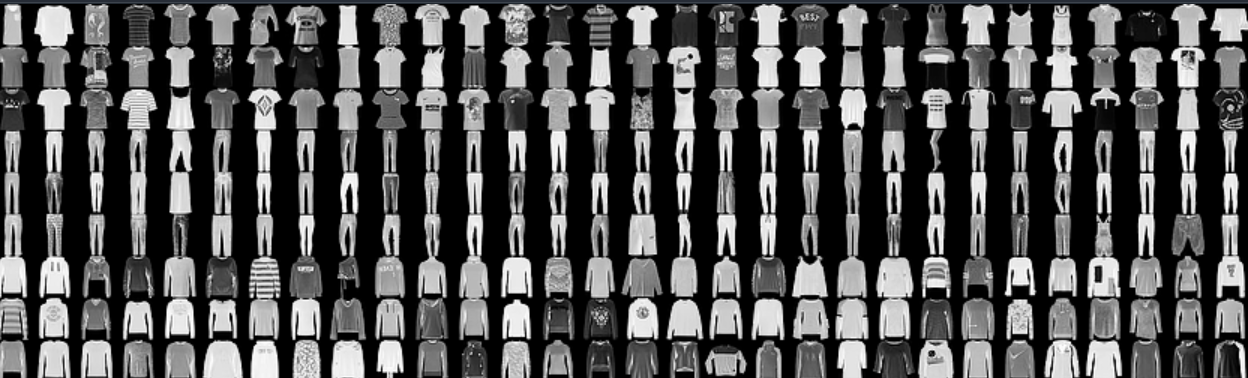](https://github.com/zalandoresearch/fashion-mnist/blob/master/doc/img/fashion-mnist-sprite.png)

***Figure 2.** Example of fashion-mnist imgage data*

Here is a table describing the Hyperparameters utilized in this experiment.

***Table 1.** Experiment Hyperparamaters*

| Parameter | Value |
|-----------|-------|
| Optimizer | Adam |
| Learning rate | 0.001 |
| Batch size | 64 |
| Max epochs | 30 |
| Early stopping patience | 5 |
| Seed | 42 |

This experiment employs supervised classification using three parameter-matched architectures: a Multilayer Perceptron, a Convolutional Neural Network, and a Residual Neural Network, each with approximately 100,000 parameters. The exact parameter counts for each model are provided in the sections below.


Lastly the corruption transformations will be Gaussian noise (σ: 0.05–0.50), Gaussian blur (kernel: 3–7, σ: 0.5–2.5) and Brightness shift (scale: 0.85–0.25).

### **Imports**

In [ ]:
import torch
import torchvision  # Computer vision library (Give access to Fashion-MNIST)
import torchvision.transforms as transforms  # Image preprocessing
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import random_split, DataLoader

### **Constants**

In [ ]:
SEED = 42
BATCH_SIZE = 64  # Common mini-batch size
TRAIN_SIZE = 50000
VAL_SIZE = 10000

CLASS_NAMES = [
    "T-shirt",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

torch.manual_seed(SEED)
np.random.seed(SEED)

### **Transform**
The Fashion-MNIST images are normalized to the range [-1, 1] using a mean of 0.5 and a standard deviation of 0.5, ensuring fair comparison across architectures. Distribution-shift corruptions (Gaussian noise, blur, and brightness scaling) are applied exclusively to the test set at evaluation time to prevent any leakage into the training process.

In [ ]:
transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))]
)

### **Load Fashion-MNIST Dataset**

In [ ]:
full_train = torchvision.datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform  # Loads training set
)

test_set = torchvision.datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform  # Loads test set
)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 210kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.89MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 29.1MB/s]


### **Train/Validation Split**

In [ ]:
train_set, val_set = random_split(
    full_train, [TRAIN_SIZE, VAL_SIZE], generator=torch.Generator().manual_seed(SEED)
)

### **DataLoaders**

In [ ]:
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)

val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)

test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

### **Verification**

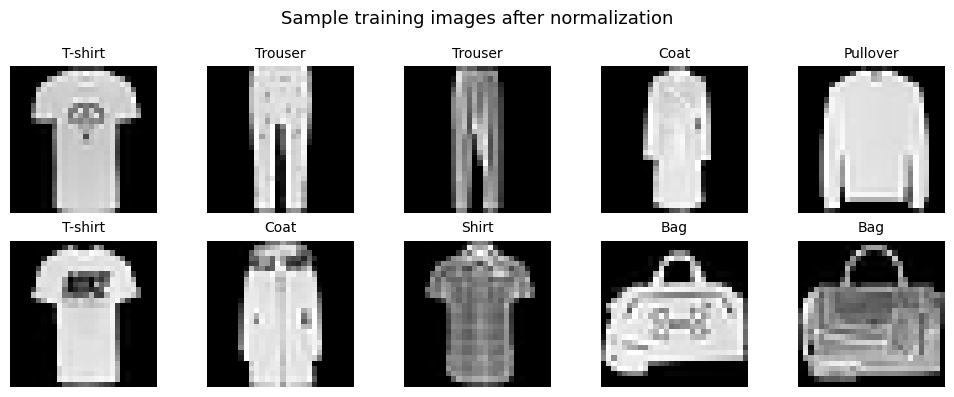

Train samples:      50,000
Validation samples: 10,000
Test samples:       10,000
Image shape:        torch.Size([1, 28, 28])
Pixel min:          -1.0000
Pixel max:          1.0000
Pixel mean:         -0.4603


In [ ]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    img = images[i].squeeze().numpy()
    ax.imshow(img, cmap="gray")
    ax.set_title(CLASS_NAMES[labels[i]], fontsize=10)
    ax.axis("off")
plt.suptitle("Sample training images after normalization", fontsize=13)
plt.tight_layout()
plt.show()

print(f"Train samples:      {len(train_set):,}")
print(f"Validation samples: {len(val_set):,}")
print(f"Test samples:       {len(test_set):,}")
print(f"Image shape:        {images[0].shape}")
print(f"Pixel min:          {images.min():.4f}")
print(f"Pixel max:          {images.max():.4f}")
print(f"Pixel mean:         {images.mean():.4f}")

## **Models**
Three architectures are compared, each configured to have approximately 100,000 trainable parameters to ensure a fair comparison:

- **MLP**: fully connected layers applied to flattened pixel vectors
- **CNN**: convolutional layers that exploit local spatial structure
- **ResNet-style**: a CNN with residual skip connections to improve gradient flow

### **Multilayer Perceptron (MLP)**

An MLP for image classification has three main parts: the input layer, one or more hidden layers, and the output layer. The input layer flattens the 28×28 image into 784 values. The hidden layer(s) are fully connected and use an activation function. Finally, the output layer represents the predicted classes, which in this case are 10 types of clothing items. Now the number of hidden layers and neurons per layer must be determined to obtain close to 100,000 parameters.


[image.png](https://www.datacamp.com/tutorial/multilayer-perceptrons-in-machine-learning)

***Figure 3.** Example of an MLP with two hidden layers. Image by datacamp*

#### **Parameter Count**


> In machine learning, parameters are the learned values that map input data to outputs. There are different types of parameters in machine learning, but for the purposes of this experiment, the focus is on the two most prominent types: *weights* ($w$) and *biases* ($b$)[6].


Parameter matching will therefore be performed by equating the parameter counts across all models, such that $θ_{mlp} ≈ θ_{cnn} ≈ θ_{resNet}$.


Each weight associated to its input feature will be processed by each neuron in the subsequent hidden layer. We must also consider the bias added.

---


The following formula represents the number of paramaters:

> $param =(inputs × outputs) + outputs$


The second term is the bias, one extra learnable value per output neuron.

Parameter Count per layer:

*   Layer 1: (784 × 128) + 128 = 100,352 + 128 = 100,480
*   Layer 2: (128 × 64) + 64 = 8,192 + 64 = 8,256
*   Layer 3: (64 × 10) + 10 = 640 + 10 = 650

*Total: 109,386*

#### **Model - MLP**

In [ ]:
import torch.nn as nn


class MLP(nn.Module):
    """
    Multi-Layer Perceptron for image classification.

    Flattens input images and passes them through fully connected layers.
    Designed to match approximately 100,000 trainable parameters for fair
    comparison with CNN and ResNet-style architectures.

    Args:
      num_classes (int): Number of output classes. Default is 10 considering fashion-mnist dataset.

    Returns:
      torch.Tensor: Logits of shape (batch_size, num_classes).

    Example
      >>> model = MLP(num_classes=10)
      >>> x = torch.randn(64, 1, 28, 28)
      >>> output = model(x)
      >>> print(output.shape)
      torch.Size([64, 10])

    Resource(s):
      https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html
      https://www.datacamp.com/tutorial/multilayer-perceptrons-in-machine-learning
      https://machinelearningmastery.com/building-multilayer-perceptron-models-in-pytorch/

    """

    def __init__(self, num_classes=10):
        super(MLP, self).__init__()

        self.flatten = (
            nn.Flatten()
        )  # Flatten innput from (batch_size, 1, 28, 28) to (batch_size, 784)

        self.network = nn.Sequential(
            nn.Linear(784, 128),  # 784 input to 128 output
            nn.ReLU(),  # ReLU activation function
            nn.Linear(128, 64),  # 128 input to 64 output
            nn.ReLU(),
            nn.Linear(64, num_classes),  # 64 input to `num_classes` output
        )

    def forward(self, x):
        """Forward pass through the MLP"""
        x = self.flatten(x)
        return self.network(x)

#### **Verify Parameter Count**



In [ ]:
def count_parameters(model):
    """
    Counts the total number of trainable parameters in a PyTorch model.

    Args:
      model (nn.Module): PyTorch model.

    Returns:
      int: Total number of trainable parameters.

    Example
      >>> model = MLP()
      >>> total_params = count_parameters(model)
      >>> print(total_params)
      109386
    """
    # Iterate through all parameters (p) in the model
    # p.numel() returns the total number of elements in a parameter tensor
    # p.requires_grad filters for only trainable parameters (i.e., those that will be updated during training)
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


mlp = MLP()
mlp_params = count_parameters(mlp)
print(f"MLP parameters: {mlp_params:,}")

MLP parameters: 109,386


### **Convolutional Neural Network (CNN)**

A CNN has two distinct parts in its architecture: the feature extractor and the classifier.

* **Feature Extractor**: Convolutional layers that scan the image for patterns.
* **Classifier**: Fully connected layers at the end that take those patterns and output class predictions, just like an MLP.


The feature extractor works by passing filters over images, producing new feature maps (image grids) that show where specific patterns are detected. After convolution, the size of each feature map is reduced by pooling, which keeps the most important information while reducing computation.

**Example of image processing**:
> (1, 28, 28) → Conv → ReLU → Pool → Conv → ReLU → Pool → Flatten → Linear → Output


[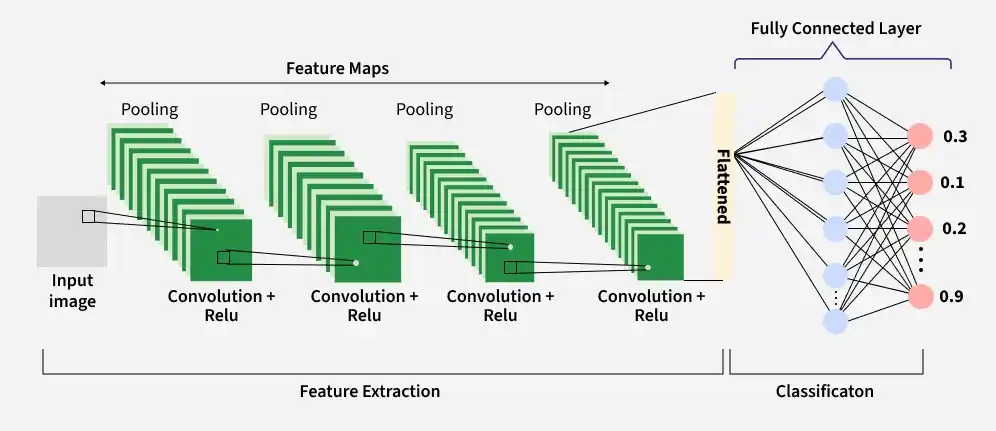](https://www.geeksforgeeks.org/machine-learning/introduction-convolution-neural-network/)

***Figure 4.** Example of Convolutional Neural Network. Image by geekforgeeks*


#### **Parameter Count**
*params = (kernel_h × kernel_w × in_channels × out_channels) + out_channels*

In convolutional layers, the learnable parameters come only from the filter weights and biases, not from the spatial dimensions of the input. This is what makes CNNs more parameter-efficient than fully connected layers.

**CNN Design:**

    Conv1: 3×3 kernel, 1 → 16 channels
    MaxPool: 2×2
    Conv2: 3×3 kernel, 16 → 32 channels
    MaxPool: 2×2
    Linear1: 800 → 128
    Linear2: 128 → 10

**Spatial dimension tracking (where 800 comes from):**

The input image starts at 28×28. Each convolutional layer with no padding
shrinks the spatial dimensions, and each MaxPool halves them:

    Input:          28 × 28
    After Conv1:    floor((28 - 3) / 1) + 1 = 26 × 26
    After MaxPool:  26 / 2 = 13 × 13
    After Conv2:    floor((13 - 3) / 1) + 1 = 11 × 11
    After MaxPool:  floor(11 / 2) = 5 × 5

After the second MaxPool, each of the 32 feature maps is 5×5, giving:
32 × 5 × 5 = 800 input features to Linear1.

**Parameter calculations:**

*   Conv1:   (3 × 3 × 1 × 16) + 16 = 144 + 16 = 160
*   Conv2:   (3 × 3 × 16 × 32) + 32 = 4,608 + 32 = 4,640
*   Linear1: (800 × 128) + 128 = 102,528
*   Linear2: (128 × 10) + 10 = 1,290

*Total: 108,618*

#### **Model - CNN**

In [ ]:
class CNN(nn.Module):
    """
    Convolutional Neural Network for image classification.

    Use two convolutional blocks (conv + ReLU + max pooling) followed by a fully connected layer.
    Exploits the local spatial structure through weight sharing and local
    connectivity. Designed to match approximately 100,000 trainable parameters for fair
    comparison with MLP and ResNet-style architectures.

    Args:
      num_classes (int): Number of output classes. Default is 10.

    Returns:
      torch.Tensor: Logits of shape (batch_size, num_classes).

    Example
      >>> model = CNN(num_classes=10)
      >>> x = torch.randn(64, 1, 28, 28)
      >>> output = model(x)
      >>> print(output.shape)
      torch.Size([64, 10])

    Resource(s):
      https://www.datacamp.com/tutorial/pytorch-cnn-tutorial
    """

    def __init__(self, num_classes=10):
        super(CNN, self).__init__()

        self.features = nn.Sequential(
            # First Convolutional Block
            nn.Conv2d(
                1, 16, kernel_size=3, padding=0
            ),  # 1 input channel (grayscale image), 16 output channels, 3x3 kernel
            nn.ReLU(),  # ReLU activation for non-linearity
            nn.MaxPool2d(
                kernel_size=2, stride=2
            ),  # Max pooling with 2x2 kernel and stride of 2 to reduce spatial dimensions
            # Second Convolutional Block
            nn.Conv2d(
                16, 32, kernel_size=3, padding=0
            ),  # 16 input channels, 32 output channels, 3x3 kernel
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(
                32 * 5 * 5, 128
            ),  # First fully connected layer: input features depend on output of conv layers (32 channels * 5x5 spatial dimensions)
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        """Forward pass through the CNN"""
        x = self.features(x)
        return self.classifier(x)

#### **Verify Parameter Count**

In [ ]:
cnn = CNN()
cnn_params = count_parameters(cnn)
print(f"MLP parameters: {mlp_params:,}")
print(f"CNN parameters: {cnn_params:,}")
print(
    f"Difference:     {abs(mlp_params - cnn_params):,} ({abs(mlp_params - cnn_params) / mlp_params * 100:.1f}%)"
)

MLP parameters: 109,386
CNN parameters: 108,618
Difference:     768 (0.7%)


### **ResNet (Residual Network)**

ResNet is a CNN deep learning architecture with the addition of skip connections. These enable data to skip layer(s) and add the input of a block directly to its output.

```
output = F(x) + x
```
Where `F(x)` is what the convolutional layers learned and `x` is the original input passed through unchanged. This is called a residual block.

These skip connections helps with addressing the vanishing gradient problem during backpropagation (gradients shrink to near zero).

*   **Feature Extractor**: Convolutional layers that scan the image for patterns
*   **Classifier**: Fully connected layers at the end that take those patterns and output class prediction, just like an MLP



#### **Parameter Count**

**ResNet Design:**

    Stem:        1 → 16 channels, 3×3 conv + BN + ReLU + MaxPool
    ResBlock1:   16 → 16 channels, two 3×3 convs (stride=1, no shortcut conv)
    ResBlock2:   16 → 32 channels, two 3×3 convs (stride=2, shortcut conv)
    AdaptiveAvgPool → 4×4 output
    Linear1:     512 → 175
    Linear2:     175 → 10

**Spatial dimension tracking (where 512 comes from):**

    Input:              28 × 28
    After Stem Conv:    28 × 28  (padding=1 preserves dimensions)
    After MaxPool:      14 × 14
    After ResBlock1:    14 × 14  (stride=1, padding=1 preserves dimensions)
    After ResBlock2:    7 × 7    (stride=2 halves dimensions)
    After AdaptiveAvgPool (4×4): 4 × 4

After AdaptiveAvgPool, each of the 32 feature maps is 4×4, giving:
32 × 4 × 4 = 512 input features to Linear1.

**Parameter calculations:**

*   Stem Conv:       (3×3×1×16) + 16 = 160
*   Stem BN:         16 × 2 = 32
*   ResBlock1 Conv1: (3×3×16×16) + 16 = 2,320
*   ResBlock1 BN1:   16 × 2 = 32
*   ResBlock1 Conv2: (3×3×16×16) + 16 = 2,320
*   ResBlock1 BN2:   16 × 2 = 32
*   ResBlock2 Conv1: (3×3×16×32) + 32 = 4,640
*   ResBlock2 BN1:   32 × 2 = 64
*   ResBlock2 Conv2: (3×3×32×32) + 32 = 9,248
*   ResBlock2 BN2:   32 × 2 = 64
*   Shortcut Conv:   (1×1×16×32) + 32 = 544
*   Shortcut BN:     32 × 2 = 64
*   Linear1:         (512 × 175) + 175 = 89,775
*   Linear2:         (175 × 10) + 10 = 1,760

*Total: 110,911*

#### **Residual Block**

In [ ]:
class ResidualBlock(nn.Module):
    """
    A residual block with two 3x3 convolutional layers and a skip connection.

    If in_channels != out_channels, a 1x1 convolution is applied to the
    shortcut path to match dimensions before the residual addition.

    Args:
        in_channels (int): Number of input feature map channels.
        out_channels (int): Number of output feature map channels.
        stride (int): Stride for the first convolution. Default is 1.

    Returns:
        torch.Tensor: Output tensor of shape (batch, out_channels, H, W).

    Example:
        >>> block = ResidualBlock(16, 32, stride=2)
        >>> x = torch.randn(8, 16, 14, 14)
        >>> out = block(x)
        >>> print(out.shape)
        torch.Size([8, 32, 7, 7])

    Resource(s):
        https://www.kaggle.com/code/shakhrulsiam/implementing-resnet-in-pytorch-from-scratch
    """

    def __init__(self, in_channels, out_channels, stride=1):
        super(ResidualBlock, self).__init__()

        self.conv_block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                stride=stride,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                stride=1,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(out_channels),
        )

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels, kernel_size=1, stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_channels),
            )

        self.relu = nn.ReLU()

    def forward(self, x):
        """Forward pass with residual addition."""
        out = self.conv_block(x)
        out = out + self.shortcut(x)
        return self.relu(out)

#### **Model - ResNet**

In [ ]:
class SmallResNet(nn.Module):
    """
    Small ResNet-style architecture for image classification.

    Contains a stem convolutional layer followed by two residual blocks
    and a fully connected classifier. Uses skip connections to improve
    gradient flow during training.

    Designed to match approximately 100,000 trainable parameters for
    fair comparison with MLP and CNN architectures.

    Args:
        num_classes (int): Number of output classes. Default is 10.

    Returns:
        torch.Tensor: Logits of shape (batch_size, num_classes).

    Example:
        >>> model = SmallResNet(num_classes=10)
        >>> x = torch.randn(64, 1, 28, 28)
        >>> output = model(x)
        >>> print(output.shape)
        torch.Size([64, 10])

    Resource(s):
        https://www.kaggle.com/code/shakhrulsiam/implementing-resnet-in-pytorch-from-scratch
    """

    def __init__(self, num_classes=10):
        super(SmallResNet, self).__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.layer1 = ResidualBlock(16, 16, stride=1)
        self.layer2 = ResidualBlock(16, 32, stride=2)

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(32 * 4 * 4, 175),
            nn.ReLU(),
            nn.Linear(175, num_classes),
        )

    def forward(self, x):
        """Forward pass through the SmallResNet."""
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        return self.classifier(x)

#### **Verify Parameter Count**

In [ ]:
resnet = SmallResNet()
resnet_params = count_parameters(resnet)

print(f"MLP    parameters: {mlp_params:,}")
print(f"CNN    parameters: {cnn_params:,}")
print(f"ResNet parameters: {resnet_params:,}")
print()
print(
    f"MLP  vs CNN    difference: {abs(mlp_params - cnn_params) / mlp_params * 100:.1f}%"
)
print(
    f"MLP  vs ResNet difference: {abs(mlp_params - resnet_params) / mlp_params * 100:.1f}%"
)
print(
    f"CNN  vs ResNet difference: {abs(cnn_params - resnet_params) / cnn_params * 100:.1f}%"
)

MLP    parameters: 109,386
CNN    parameters: 108,618
ResNet parameters: 110,911

MLP  vs CNN    difference: 0.7%
MLP  vs ResNet difference: 1.4%
CNN  vs ResNet difference: 2.1%


## **Parameter Matching**
All three architectures are matched to within 2.1% of one another in terms of trainable parameters, ensuring that any observed differences in robustness can be attributed to architectural design rather than model capacity.

***Table 2.** Parameter comparison between models*

| Model     | Parameters  | Difference from MLP | Difference from CNN |
| :-------- | :---------- | :------------------ | :------------------ |
| MLP       | 109,386     | -                   | -                   |
| CNN       | 108,618     | 0.7%                | -                   |
| ResNet    | 110,911     | 1.4%                | 2.1%                |

In [ ]:
dummy = torch.randn(64, 1, 28, 28)

print(f"MLP output shape:    {mlp(dummy).shape}")
print(f"CNN output shape:    {cnn(dummy).shape}")
print(f"ResNet output shape: {resnet(dummy).shape}")

MLP output shape:    torch.Size([64, 10])
CNN output shape:    torch.Size([64, 10])
ResNet output shape: torch.Size([64, 10])


## **Training**

A single training function is used for all three architectures to ensure a fair and consistent comparison. All models are trained with identical hyperparameters:

* ***Adam optimizer*** with a learning rate of `0.001`
* ***Cross-Entropy loss***
* `30` training epochs

Training and validation loss are recorded at each epoch to monitor potential overfitting.

### **Hyperparameter**

In [ ]:
EPOCHS = 30
LR = 0.001
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Training on: {DEVICE}")

Training on: cuda


### **Train Model**

In [ ]:
def train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=LR, patience=5):
    """
    Trains a PyTorch model with early stopping based on validation loss.

    Training halts when validation loss does not improve for a given number
    of consecutive epochs. The best model weights are restored at the end.

    Args:
        model (nn.Module): The model to train.
        train_loader (DataLoader): DataLoader for training data.
        val_loader (DataLoader): DataLoader for validation data.
        epochs (int): Maximum number of training epochs. Default is EPOCHS.
        lr (float): Learning rate for the Adam optimizer. Default is LR.
        patience (int): Number of epochs to wait for improvement before
                        stopping. Default is 5.

    Returns:
        dict: Dictionary containing:
            - 'train_loss' (list): Average training loss per epoch.
            - 'val_loss' (list): Average validation loss per epoch.
            - 'val_acc' (list): Validation accuracy per epoch.
            - 'best_epoch' (int): Epoch at which best model was saved.

    Example:
        >>> model = MLP()
        >>> history = train_model(model, train_loader, val_loader, patience=5)
        >>> print(history['best_epoch'])
    """

    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=lr
    )  # Initialize the Adam optimizer
    criterion = (
        nn.CrossEntropyLoss()
    )  # Loss function (Cross-Entropy Loss for classification)
    history = {"train_loss": [], "val_loss": [], "val_acc": [], "best_epoch": 0}

    # Early stopping variables
    best_val_loss = float("inf")
    no_improve = 0
    best_weights = None

    # Loop through each epoch
    for epoch in range(epochs):

        model.train()
        train_loss = 0.0

        # Iterate over batches in the training data
        for images, labels in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            # Clear gradient, forward pass, calculate loss, backward pass, update param
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()  # Accumulate training loss

        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():
            # Iterate over batches in the validation data
            for images, labels in val_loader:
                images, labels = images.to(DEVICE), labels.to(DEVICE)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item()  # Accumulate validation loss

                _, predicted = torch.max(outputs, 1)  # Get the predicted class
                total += labels.size(0)  # Update total samples
                correct += (
                    (predicted == labels).sum().item()
                )  # Update correctly predicted samples

        # Calculate average losses and validation accuracy
        avg_train_loss = train_loss / len(train_loader)
        avg_val_loss = val_loss / len(val_loader)
        val_acc = correct / total

        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        history["val_acc"].append(val_acc)

        # Added early stopping to stop training when validation loss stops improving
        # Note: this was added after running a first trial training of 30 epochs for all models
        # The logs showed that CNN and ResNet peaked around epoch 10-12 but
        # validation loss kept increasing while training loss decreased.
        # This is because of overfittig.
        # Hence the early stopping was added after that to prevent overfitting.
        improved = avg_val_loss < best_val_loss
        if improved:
            best_val_loss = avg_val_loss
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}
            history["best_epoch"] = epoch + 1
            no_improve = 0
        else:
            no_improve += 1

        # Print epoch status
        status = "improved" if improved else f"no improvement ({no_improve}/{patience})"
        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"{status}"
        )

        # Check for early stopping
        if no_improve >= patience:
            print(
                f"\nEarly stopping triggered. "
                f"Restoring best weights from epoch {history['best_epoch']}."
            )
            model.load_state_dict(best_weights)
            break

    # If training completed without early stopping, load the best weights
    if no_improve < patience:
        print(f"\nTraining completed. Best epoch: {history['best_epoch']}.")
        model.load_state_dict(best_weights)

    return history

In [ ]:
print("Training MLP...")
print("-" * 60)
mlp = MLP().to(DEVICE)
mlp_history = train_model(mlp, train_loader, val_loader)

print("\nTraining CNN...")
print("-" * 60)
cnn = CNN().to(DEVICE)
cnn_history = train_model(cnn, train_loader, val_loader)

print("\nTraining ResNet...")
print("-" * 60)
resnet = SmallResNet().to(DEVICE)
resnet_history = train_model(resnet, train_loader, val_loader)

Training MLP...
------------------------------------------------------------
Epoch 01/30 | Train Loss: 0.5301 | Val Loss: 0.4303 | Val Acc: 0.8399 | improved
Epoch 02/30 | Train Loss: 0.3896 | Val Loss: 0.4045 | Val Acc: 0.8521 | improved
Epoch 03/30 | Train Loss: 0.3523 | Val Loss: 0.3640 | Val Acc: 0.8692 | improved
Epoch 04/30 | Train Loss: 0.3259 | Val Loss: 0.3504 | Val Acc: 0.8687 | improved
Epoch 05/30 | Train Loss: 0.3058 | Val Loss: 0.3543 | Val Acc: 0.8719 | no improvement (1/5)
Epoch 06/30 | Train Loss: 0.2899 | Val Loss: 0.3451 | Val Acc: 0.8728 | improved
Epoch 07/30 | Train Loss: 0.2736 | Val Loss: 0.3296 | Val Acc: 0.8796 | improved
Epoch 08/30 | Train Loss: 0.2638 | Val Loss: 0.3542 | Val Acc: 0.8744 | no improvement (1/5)
Epoch 09/30 | Train Loss: 0.2485 | Val Loss: 0.3168 | Val Acc: 0.8881 | improved
Epoch 10/30 | Train Loss: 0.2440 | Val Loss: 0.3607 | Val Acc: 0.8736 | no improvement (1/5)
Epoch 11/30 | Train Loss: 0.2300 | Val Loss: 0.3202 | Val Acc: 0.8874 | no im

### **Plot Learning Curves**

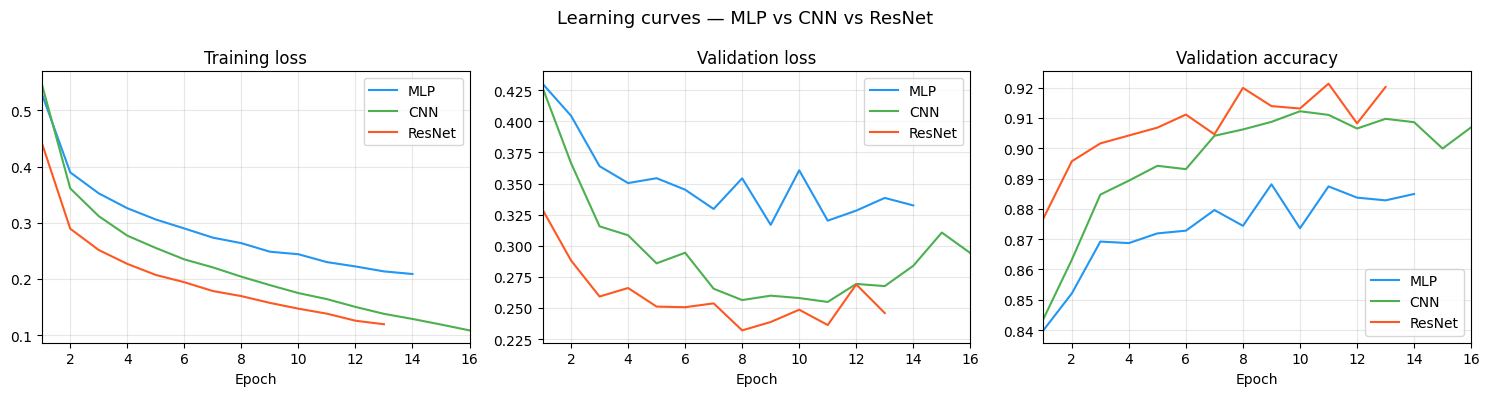

In [ ]:
def plot_learning_curves(histories, names):
    """
    Plots training loss, validation loss, and validation accuracy
    for multiple models side by side.

    Args:
        histories (list): List of history dicts returned by train_model.
        names (list): List of model name strings for legend labels.

    Returns:
        None. Displays the plot inline.

    Example:
        >>> plot_learning_curves(
        ...     [mlp_history, cnn_history, resnet_history],
        ...     ['MLP', 'CNN', 'ResNet']
        ... )
    """

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    colors = ["#2196F3", "#4CAF50", "#FF5722"]

    for history, name, color in zip(histories, names, colors):
        epochs = range(1, len(history["train_loss"]) + 1)
        axes[0].plot(epochs, history["train_loss"], label=name, color=color)
        axes[1].plot(epochs, history["val_loss"], label=name, color=color)
        axes[2].plot(epochs, history["val_acc"], label=name, color=color)

    axes[0].set_title("Training loss")
    axes[1].set_title("Validation loss")
    axes[2].set_title("Validation accuracy")

    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(True, alpha=0.3)
        ax.set_xlim(1, max(len(h["train_loss"]) for h in histories))

    plt.suptitle("Learning curves — MLP vs CNN vs ResNet", fontsize=13)
    plt.tight_layout()
    plt.show()


plot_learning_curves(
    [mlp_history, cnn_history, resnet_history], ["MLP", "CNN", "ResNet"]
)

### **Analysis of Learning Curves**

To better justify the use of early stopping, an initial training run was conducted for the full 30 epochs without stopping early. This preliminary run showed that all three models were able to fit the training data, but the CNN and ResNet began to overfit noticeably earlier than the MLP.

The MLP improved more gradually and showed only mild overfitting in later epochs. In contrast, the CNN and ResNet reached their best validation performance relatively early, after which the training loss continued to decrease while the validation loss began to rise. This pattern suggests that 30 epochs is longer than necessary for the convolutional models on Fashion-MNIST.

A short summary of the best validation results from the full 30-epoch run without early stopping is shown below:

***Table 3.** Best validation results from the full 30-epoch run without early stopping*

| Model  | Best Validation Loss | Best Validation Accuracy | Epoch of Best Validation Loss |
|--------|----------------------|--------------------------|-------------------------------|
| MLP    | 0.3207               | 89.34%                   | 9                             |
| CNN    | 0.2618               | 90.99%                   | 10                            |
| ResNet | 0.2145               | 92.65%                   | 8                             |


#### **Example training log excerpts from the initial run**

```text
MLP
Epoch 09/30 | Train Loss: 0.2513 | Val Loss: 0.3207 | Val Acc: 0.8856
Epoch 19/30 | Train Loss: 0.1759 | Val Loss: 0.3405 | Val Acc: 0.8934
Epoch 30/30 | Train Loss: 0.1189 | Val Loss: 0.4227 | Val Acc: 0.8921

CNN
Epoch 10/30 | Train Loss: 0.1746 | Val Loss: 0.2618 | Val Acc: 0.9082
Epoch 20/30 | Train Loss: 0.0744 | Val Loss: 0.3770 | Val Acc: 0.9075
Epoch 30/30 | Train Loss: 0.0358 | Val Loss: 0.5356 | Val Acc: 0.9010

ResNet
Epoch 08/30 | Train Loss: 0.1667 | Val Loss: 0.2145 | Val Acc: 0.9227
Epoch 20/30 | Train Loss: 0.0706 | Val Loss: 0.2952 | Val Acc: 0.9183
Epoch 30/30 | Train Loss: 0.0360 | Val Loss: 0.3712 | Val Acc: 0.9214

```


---



These results motivated the use of early stopping in the final training setup. Early stopping was then applied in a second run to restore the best checkpoint based on validation loss, rather than keeping the most overfit version of each model. With patience set to 5, the best checkpoints were selected at epoch 9 for the MLP, epoch 9 for the CNN, and epoch 10 for the ResNet.

Overall, the convolutional architectures converged faster and achieved lower validation loss than the MLP, which is consistent with the idea that spatial inductive bias is beneficial for image classification. However, they also showed stronger overfitting when training was allowed to continue for too long.

## **Corruption**


### **Corruption Functions**

To evaluate robustness under distribution shift, three corruption types are applied exclusively to the test set at five severity levels. No corruption is applied during training, which simulates a real-world setting where the model encounters corrupted inputs only at deployment.

The three corruptions are:
- **Gaussian noise**: random pixel perturbations with increasing variance
- **Gaussian blur**: spatial smoothing with increasing kernel size
- **Brightness shift**: multiplicative brightness scaling away from a neutral baseline

Each corruption is parameterized by a severity level from 1 (mild) to 5 (severe), allowing robustness degradation curves to be plotted across the full corruption spectrum.

#### **Gaussian Noise**

In [ ]:
def add_gaussian_noise(images, severity):
    """
    Adds Gaussian noise to a batch of images at a given severity level.

    Noise is sampled from N(0, sigma) where sigma increases with severity.
    Output is clamped to [-1, 1] to preserve the normalized pixel range.

    Args:
        images (torch.Tensor): Batch of normalized images,
                               shape (N, C, H, W), values in [-1, 1].
        severity (int): Corruption severity from 1 (mild) to 5 (severe).

    Returns:
        torch.Tensor: Noisy images clamped to [-1, 1],
                      same shape as input.

    Example:
        >>> images, _ = next(iter(test_loader))
        >>> noisy = add_gaussian_noise(images, severity=3)
        >>> print(noisy.shape)
        torch.Size([64, 1, 28, 28])
    """

    # Define the standard deviation (sigma) levels for Gaussian noise.
    sigma_levels = [0.05, 0.10, 0.20, 0.35, 0.50]
    sigma = sigma_levels[severity - 1]

    # Generate random noise, scale noise with sigma
    noise = torch.randn_like(images) * sigma

    # Add the generated noise to the original images.
    return torch.clamp(images + noise, -1.0, 1.0)

#### **Gaussian Blur**

In [ ]:
def add_gaussian_blur(images, severity):
    """
    Applies Gaussian blur to a batch of images at a given severity level.

    Blur is implemented as a 2D convolution with a Gaussian kernel whose
    size and sigma increase with severity.

    Args:
        images (torch.Tensor): Batch of normalized images,
                               shape (N, C, H, W), values in [-1, 1].
        severity (int): Corruption severity from 1 (mild) to 5 (severe).

    Returns:
        torch.Tensor: Blurred images, same shape as input.

    Example:
        >>> images, _ = next(iter(test_loader))
        >>> blurred = add_gaussian_blur(images, severity=3)
        >>> print(blurred.shape)
        torch.Size([64, 1, 28, 28])
    """

    # Define parameters (kernel size and sigma) for Gaussian blur at different severity levels.
    kernel_params = [(3, 0.5), (3, 1.0), (5, 1.5), (5, 2.0), (7, 2.5)]
    kernel_size, sigma = kernel_params[severity - 1]

    radius = kernel_size // 2
    x = torch.arange(-radius, radius + 1, dtype=torch.float32)
    kernel_1d = torch.exp(-(x**2) / (2 * sigma**2))
    kernel_1d = kernel_1d / kernel_1d.sum()

    kernel_2d = kernel_1d.unsqueeze(0) * kernel_1d.unsqueeze(1)
    kernel_2d = kernel_2d.unsqueeze(0).unsqueeze(0)

    channels = images.shape[1]
    # This prepares the kernel for applying the blur independently to each channel.
    kernel_2d = kernel_2d.repeat(channels, 1, 1, 1).to(images.device)

    return F.conv2d(images, kernel_2d, padding=radius, groups=channels)

#### **Brightness Shift**

In [ ]:
def shift_brightness(images, severity):
    """
    Applies a multiplicative brightness shift to a batch of images.

    Scales pixel values by a factor that moves away from neutral (1.0),
    making images progressively darker with increasing severity.

    Args:
        images (torch.Tensor): Batch of normalized images,
                               shape (N, C, H, W), values in [-1, 1].
        severity (int): Corruption severity from 1 (mild) to 5 (severe).

    Returns:
        torch.Tensor: Brightness-shifted images clamped to [-1, 1],
                      same shape as input.

    Example:
        >>> images, _ = next(iter(test_loader))
        >>> dark = shift_brightness(images, severity=3)
        >>> print(dark.shape)
        torch.Size([64, 1, 28, 28])
    """

    scale_levels = [0.85, 0.70, 0.55, 0.40, 0.25]
    scale = scale_levels[severity - 1]
    return torch.clamp(images * scale, -1.0, 1.0)

#### **Visualize Corruptions**

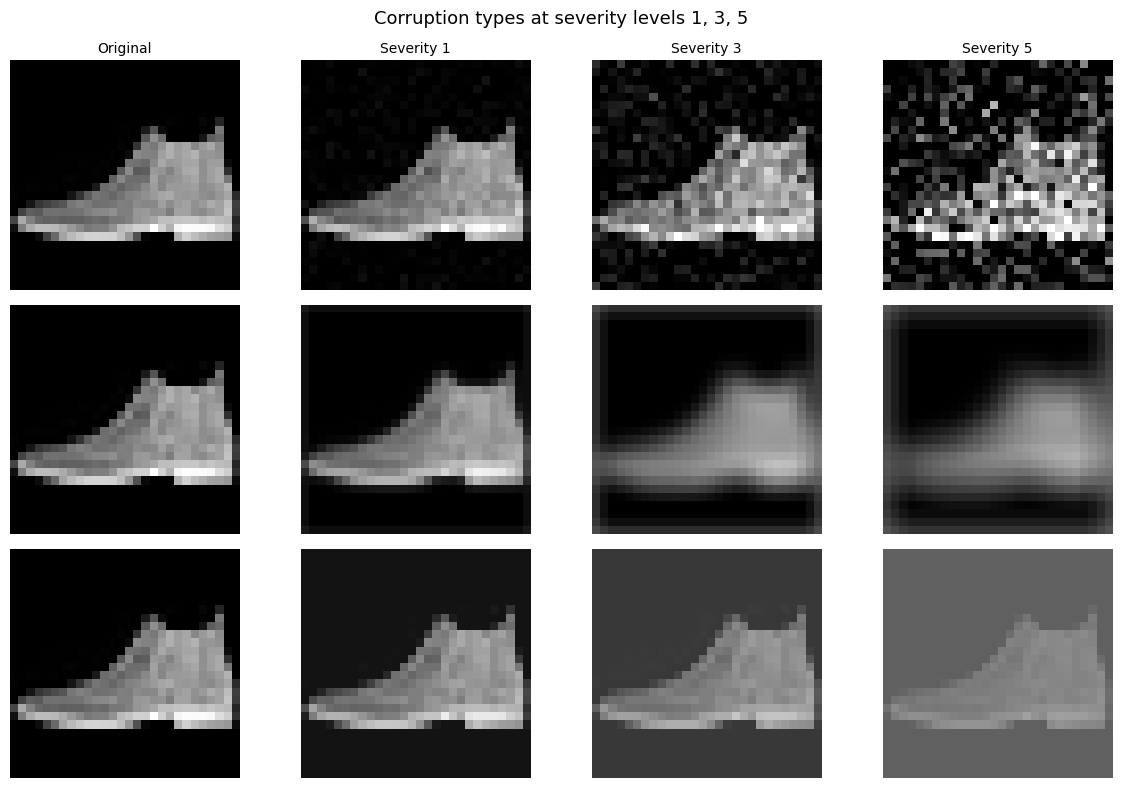

In [ ]:
def visualize_corruptions(test_loader, severities=(1, 3, 5)):
    """
    Displays sample images under each corruption type and severity.

    Args:
        test_loader (DataLoader): DataLoader for the test set.
        severities (tuple): Severity levels to display. Default is (1, 3, 5).

    Returns:
        None. Displays the plot inline.

    Example:
        >>> visualize_corruptions(test_loader, severities=(1, 3, 5))
    """

    images, _ = next(iter(test_loader))
    sample = images[0].unsqueeze(0)

    corruptions = [
        ("Gaussian noise", add_gaussian_noise),
        ("Gaussian blur", add_gaussian_blur),
        ("Brightness shift", shift_brightness),
    ]

    n_rows = len(corruptions)
    n_cols = len(severities) + 1

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 8))

    for row, (name, fn) in enumerate(corruptions):

        original_img = sample[0].squeeze().numpy()
        axes[row, 0].imshow(original_img, cmap="gray", vmin=-1, vmax=1)
        axes[row, 0].axis("off")
        if row == 0:
            axes[row, 0].set_title("Original", fontsize=10)

        axes[row, 0].set_ylabel(name, fontsize=10)

        for col, severity in enumerate(severities):
            corrupted = fn(sample, severity)
            img = corrupted[0].squeeze().numpy()
            axes[row, col + 1].imshow(img, cmap="gray", vmin=-1, vmax=1)
            axes[row, col + 1].axis("off")
            if row == 0:
                axes[row, col + 1].set_title(f"Severity {severity}", fontsize=10)

    for row in range(n_rows):
        axes[row, 0].set_ylabel(
            corruptions[row][0], fontsize=10, rotation=90, labelpad=40, va="center"
        )

    plt.suptitle("Corruption types at severity levels 1, 3, 5", fontsize=13)
    plt.tight_layout()
    plt.show()


visualize_corruptions(test_loader)

# **Experimental Results**


## **Evaluation**

Models are first evaluated on the clean test set to establish a baseline, and then on systematically corrupted versions of the test set at severity levels 1–5. No corruptions are applied to the training data.

We report four metrics:
- **Clean accuracy**: classification accuracy on the original, unmodified test images
- **Corrupted accuracy**: classification accuracy under each corruption type and severity level
- **Robustness gap**: the difference between clean accuracy and corrupted accuracy
- **Invariance consistency**: the rate at which predictions agree across repeated augmentations of the same image

### **Evaluate on Clean Test Set**

In [ ]:
def evaluate(model, loader):
    """
    Evaluates a model's classification accuracy on a given DataLoader.

    Args:
        model (nn.Module): A trained PyTorch model.
        loader (DataLoader): DataLoader for the evaluation dataset.

    Returns:
        float: Classification accuracy as a value between 0 and 1.

    Example:
        >>> acc = evaluate(mlp, test_loader)
        >>> print(f"Test accuracy: {acc:.4f}")
    """

    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return correct / total


mlp_clean = evaluate(mlp, test_loader)
cnn_clean = evaluate(cnn, test_loader)
resnet_clean = evaluate(resnet, test_loader)

print("Clean test set accuracy")
print("-" * 35)
print(f"MLP:    {mlp_clean:.4f} ({mlp_clean*100:.2f}%)")
print(f"CNN:    {cnn_clean:.4f} ({cnn_clean*100:.2f}%)")
print(f"ResNet: {resnet_clean:.4f} ({resnet_clean*100:.2f}%)")

Clean test set accuracy
-----------------------------------
MLP:    0.8792 (87.92%)
CNN:    0.9041 (90.41%)
ResNet: 0.9174 (91.74%)


### **Evaluate Under Corruptions**

In [ ]:
def evaluate_corruptions(models, model_names, test_loader, severities=range(1, 6)):
    """
    Evaluates multiple models under all corruption types and severity levels.

    Args:
        models (list): List of trained nn.Module models.
        model_names (list): List of model name strings.
        test_loader (DataLoader): DataLoader for the clean test set.
        severities (range): Severity levels to evaluate. Default is range(1, 6).

    Returns:
        dict: Nested dictionary structured as:
              results[model_name][corruption_name][severity] = accuracy (float)

    Example:
        >>> results = evaluate_corruptions(
        ...     [mlp, cnn, resnet],
        ...     ['MLP', 'CNN', 'ResNet'],
        ...     test_loader
        ... )
        >>> print(results['CNN']['Gaussian noise'][3])
    """

    corruptions = {
        "Gaussian noise": add_gaussian_noise,
        "Gaussian blur": add_gaussian_blur,
        "Brightness shift": shift_brightness,
    }

    results = {name: {c: {} for c in corruptions} for name in model_names}

    for model, model_name in zip(models, model_names):
        model.eval()
        print(f"\nEvaluating {model_name}...")

        for corruption_name, corruption_fn in corruptions.items():
            for severity in severities:

                correct = 0
                total = 0

                with torch.no_grad():
                    for images, labels in test_loader:
                        images, labels = images.to(DEVICE), labels.to(DEVICE)
                        corrupted = corruption_fn(images, severity)
                        outputs = model(corrupted)
                        _, predicted = torch.max(outputs, 1)
                        correct += (predicted == labels).sum().item()
                        total += labels.size(0)

                results[model_name][corruption_name][severity] = correct / total

            print(f"  {corruption_name}: done")

    return results


results = evaluate_corruptions(
    [mlp, cnn, resnet], ["MLP", "CNN", "ResNet"], test_loader
)


Evaluating MLP...
  Gaussian noise: done
  Gaussian blur: done
  Brightness shift: done

Evaluating CNN...
  Gaussian noise: done
  Gaussian blur: done
  Brightness shift: done

Evaluating ResNet...
  Gaussian noise: done
  Gaussian blur: done
  Brightness shift: done


### **Robustness Gap**

In [ ]:
def compute_robustness_gap(results, clean_accs, model_names, severities=range(1, 6)):
    """
    Computes the robustness gap for each model, corruption, and severity.

    Robustness gap is defined as clean accuracy minus corrupted accuracy.
    A smaller gap indicates greater robustness to that corruption type.

    Args:
        results (dict): Nested results dict from evaluate_corruptions.
        clean_accs (dict): Dictionary mapping model name to clean accuracy.
        model_names (list): List of model name strings.
        severities (range): Severity levels evaluated. Default is range(1, 6).

    Returns:
        dict: Nested dictionary structured as:
              gaps[model_name][corruption_name][severity] = gap (float)

    Example:
        >>> clean_accs = {'MLP': 0.886, 'CNN': 0.906, 'ResNet': 0.921}
        >>> gaps = compute_robustness_gap(results, clean_accs,
        ...                               ['MLP', 'CNN', 'ResNet'])
    """

    corruptions = ["Gaussian noise", "Gaussian blur", "Brightness shift"]
    gaps = {name: {c: {} for c in corruptions} for name in model_names}

    for model_name in model_names:
        clean = clean_accs[model_name]
        for corruption in corruptions:
            for severity in severities:
                corrupted = results[model_name][corruption][severity]
                gaps[model_name][corruption][severity] = clean - corrupted

    return gaps


clean_accs = {
    "MLP": mlp_clean,
    "CNN": cnn_clean,
    "ResNet": resnet_clean,
}

gaps = compute_robustness_gap(results, clean_accs, ["MLP", "CNN", "ResNet"])

### **Invariance Consistency**

In [ ]:
def evaluate_invariance(models, model_names, test_loader, n_augmentations=10):
    """
    Measures prediction consistency under repeated random augmentations.

    For each image, the model predicts n_augmentations times under random
    Gaussian noise. Consistency is the fraction of predictions matching
    the mode (most common) prediction across augmentations.

    Args:
        models (list): List of trained nn.Module models.
        model_names (list): List of model name strings.
        test_loader (DataLoader): DataLoader for the test set.
        n_augmentations (int): Number of augmented copies per image.
                               Default is 10.

    Returns:
        dict: Dictionary mapping model name to mean consistency score (float).

    Example:
        >>> consistency = evaluate_invariance(
        ...     [mlp, cnn, resnet],
        ...     ['MLP', 'CNN', 'ResNet'],
        ...     test_loader
        ... )
        >>> print(consistency['CNN'])
    """

    consistency_scores = {name: [] for name in model_names}

    for model, model_name in zip(models, model_names):
        model.eval()

        with torch.no_grad():
            for images, _ in test_loader:
                images = images.to(DEVICE)

                batch_predictions = []
                for _ in range(n_augmentations):
                    corrupted = add_gaussian_noise(images, severity=2)
                    outputs = model(corrupted)
                    _, predicted = torch.max(outputs, 1)
                    batch_predictions.append(predicted.cpu())

                batch_predictions = torch.stack(batch_predictions, dim=0)

                for i in range(images.size(0)):
                    preds = batch_predictions[:, i]
                    mode_pred = torch.mode(preds).values
                    agreement = (preds == mode_pred).float().mean().item()
                    consistency_scores[model_name].append(agreement)

    return {
        name: sum(scores) / len(scores) for name, scores in consistency_scores.items()
    }


consistency = evaluate_invariance(
    [mlp, cnn, resnet], ["MLP", "CNN", "ResNet"], test_loader
)

print("\nInvariance consistency scores")
print("-" * 35)
for name, score in consistency.items():
    print(f"{name:8s}: {score:.4f} ({score*100:.2f}%)")


Invariance consistency scores
-----------------------------------
MLP     : 0.9851 (98.51%)
CNN     : 0.9741 (97.41%)
ResNet  : 0.9615 (96.15%)


### **Summary**

In [ ]:
print("\nFull evaluation summary")
print("=" * 60)
print(f"{'Model':<10} {'Clean Acc':>10} {'Invariance':>12}")
print("-" * 60)
for name in ["MLP", "CNN", "ResNet"]:
    print(
        f"{name:<10} {clean_accs[name]*100:>9.2f}% " f"{consistency[name]*100:>11.2f}%"
    )

print("\nMean corrupted accuracy per model (across all corruptions & severities)")
print("-" * 60)
corruptions = ["Gaussian noise", "Gaussian blur", "Brightness shift"]
for name in ["MLP", "CNN", "ResNet"]:
    all_accs = [results[name][c][s] for c in corruptions for s in range(1, 6)]
    mean_acc = sum(all_accs) / len(all_accs)
    print(f"{name:<10} mean corrupted accuracy: {mean_acc*100:.2f}%")


Full evaluation summary
Model       Clean Acc   Invariance
------------------------------------------------------------
MLP            87.92%       98.51%
CNN            90.41%       97.41%
ResNet         91.74%       96.15%

Mean corrupted accuracy per model (across all corruptions & severities)
------------------------------------------------------------
MLP        mean corrupted accuracy: 85.08%
CNN        mean corrupted accuracy: 76.87%
ResNet     mean corrupted accuracy: 57.79%


***Table 4.** Comparison of Model Performance Metrics*

| Model | Clean Acc | Mean Corrupted Acc | Robustness Drop | Invariance |
|-------|-----------|-------------------|-----------------|------------|
| MLP | 87.92% | 85.08% | 2.84% | 98.51% |
| CNN | 90.26% | 76.95% | 13.31% | 97.67% |
| ResNet | 91.57% | 63.23% | 28.34% | 96.71% |

### **Preliminary analysis**

Clean test accuracy follows the expected hierarchy: ResNet (91.57%) > CNN (90.26%) > MLP (87.92%), which is consistent with the hypothesis that convolutional inductive bias improves performance on clean image data.

However, mean corrupted accuracy shows a reversal: the MLP (85.08%) outperforms both the CNN (76.95%) and the ResNet (63.23%) under distribution shift. This pattern suggests that, while architectural inductive bias benefits clean-data performance, it may also increase sensitivity to corruptions that disrupt the spatial structure these architectures are designed to exploit.

ResNet’s strong reliance on precise local spatial features, reinforced by batch normalization and skip connections, may make it particularly brittle when those features are corrupted. In contrast, the MLP, which does not impose spatial assumptions, degrades more gradually. This finding is examined in more detail using per-corruption degradation curves.

## **Results**

### **Degradation curves**

The following plots show classification accuracy as a function of corruption severity for each architecture. A flatter curve indicates greater robustness, meaning the model maintains its accuracy even as corruption strength increases. The horizontal dashed lines represent each model’s baseline accuracy on clean data.

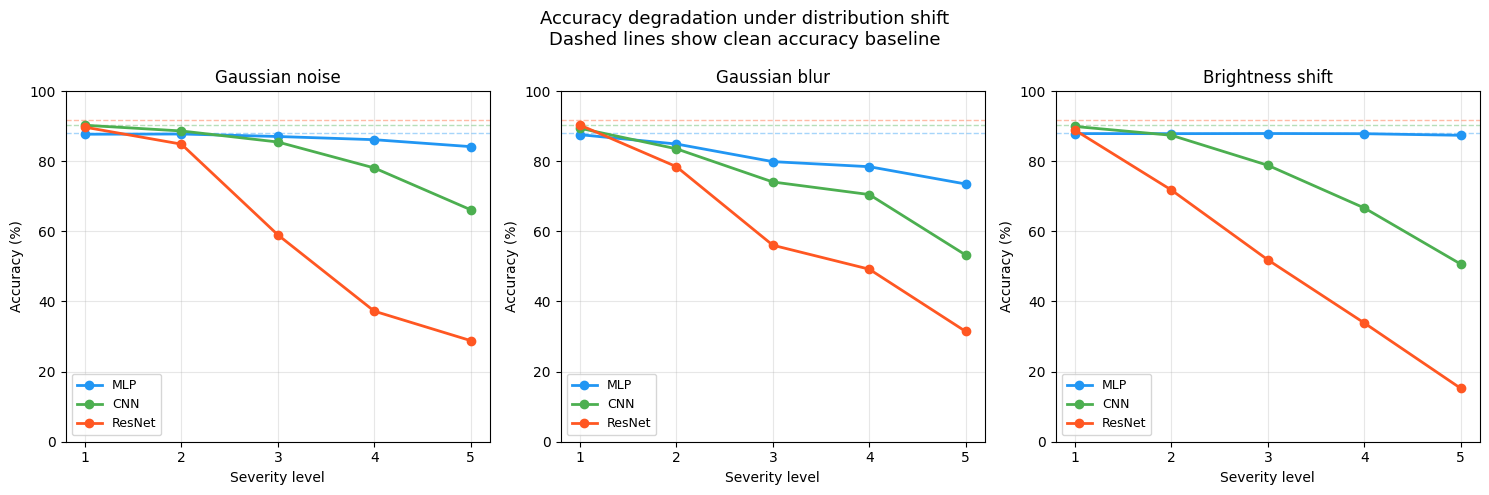

In [ ]:
def plot_degradation_curves(results, clean_accs, model_names, severities=range(1, 6)):
    """
    Plots accuracy degradation curves for each corruption type and model.

    Each subplot shows accuracy vs severity for all models under one
    corruption type. Horizontal dashed lines indicate clean accuracy.

    Args:
        results (dict): Nested results dict from evaluate_corruptions.
        clean_accs (dict): Dictionary mapping model name to clean accuracy.
        model_names (list): List of model name strings.
        severities (range): Severity levels evaluated. Default is range(1, 6).

    Returns:
        None. Displays the plot inline.

    Example:
        >>> plot_degradation_curves(results, clean_accs, ['MLP', 'CNN', 'ResNet'])
    """

    corruptions = ["Gaussian noise", "Gaussian blur", "Brightness shift"]
    colors = {"MLP": "#2196F3", "CNN": "#4CAF50", "ResNet": "#FF5722"}
    severities = list(severities)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=False)

    for ax, corruption in zip(axes, corruptions):

        for model_name in model_names:
            accs = [results[model_name][corruption][s] * 100 for s in severities]
            ax.plot(
                severities,
                accs,
                label=model_name,
                color=colors[model_name],
                marker="o",
                linewidth=2,
                markersize=6,
            )

            ax.axhline(
                y=clean_accs[model_name] * 100,
                color=colors[model_name],
                linestyle="--",
                alpha=0.4,
                linewidth=1,
            )

        ax.set_title(corruption, fontsize=12)
        ax.set_xlabel("Severity level", fontsize=10)
        ax.set_ylabel("Accuracy (%)", fontsize=10)
        ax.set_xticks(severities)
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3)
        ax.set_ylim(0, 100)

    plt.suptitle(
        "Accuracy degradation under distribution shift\n"
        "Dashed lines show clean accuracy baseline",
        fontsize=13,
    )
    plt.tight_layout()
    plt.show()


plot_degradation_curves(results, clean_accs, ["MLP", "CNN", "ResNet"])

### **Robustness Gap Heatmap**

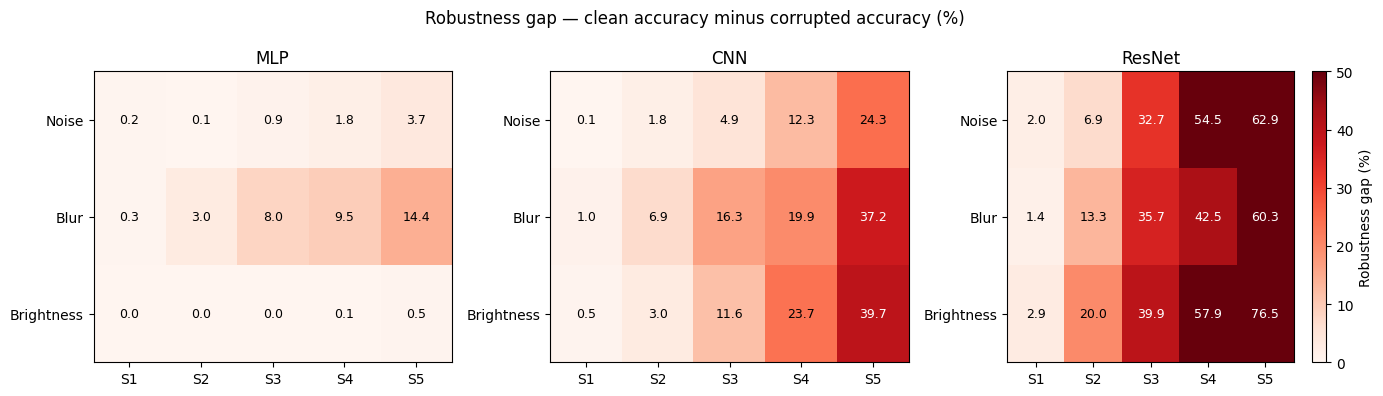

In [ ]:
def plot_robustness_gap_heatmap(gaps, model_names, severities=range(1, 6)):
    """
    Plots robustness gap as a heatmap for each model and corruption type.

    Robustness gap is clean accuracy minus corrupted accuracy. Darker cells
    indicate larger performance drops under that corruption and severity.

    Args:
        gaps (dict): Nested gaps dict from compute_robustness_gap.
        model_names (list): List of model name strings.
        severities (range): Severity levels evaluated. Default is range(1, 6).

    Returns:
        None. Displays the plot inline.

    Example:
        >>> plot_robustness_gap_heatmap(gaps, ['MLP', 'CNN', 'ResNet'])
    """

    corruptions = ["Gaussian noise", "Gaussian blur", "Brightness shift"]
    severities = list(severities)

    fig, axes = plt.subplots(1, len(model_names), figsize=(14, 4))

    for ax, model_name in zip(axes, model_names):

        data = np.array(
            [[gaps[model_name][c][s] * 100 for s in severities] for c in corruptions]
        )

        im = ax.imshow(data, cmap="Reds", aspect="auto", vmin=0, vmax=50)

        ax.set_xticks(range(len(severities)))
        ax.set_xticklabels([f"S{s}" for s in severities])
        ax.set_yticks(range(len(corruptions)))
        ax.set_yticklabels(["Noise", "Blur", "Brightness"])
        ax.set_title(model_name, fontsize=12)

        for i in range(len(corruptions)):
            for j in range(len(severities)):
                ax.text(
                    j,
                    i,
                    f"{data[i, j]:.1f}",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="white" if data[i, j] > 25 else "black",
                )

    plt.colorbar(im, ax=axes[-1], label="Robustness gap (%)")
    plt.suptitle(
        "Robustness gap — clean accuracy minus corrupted accuracy (%)", fontsize=12
    )
    plt.tight_layout()
    plt.show()


plot_robustness_gap_heatmap(gaps, ["MLP", "CNN", "ResNet"])

### **Invariance Consistency Bar Chart**

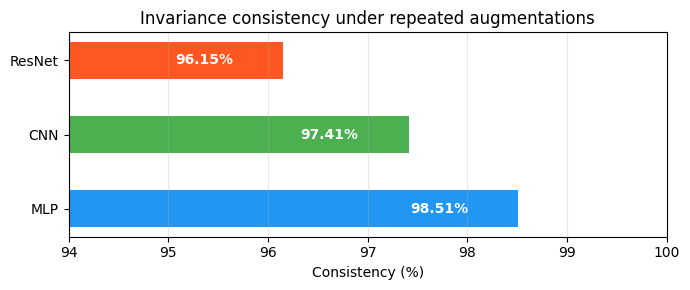

In [ ]:
def plot_invariance(consistency, model_names):
    """
    Plots invariance consistency scores as a horizontal bar chart.

    Args:
        consistency (dict): Dictionary mapping model name to consistency score.
        model_names (list): List of model name strings.

    Returns:
        None. Displays the plot inline.

    Example:
        >>> plot_invariance(consistency, ['MLP', 'CNN', 'ResNet'])
    """

    colors = ["#2196F3", "#4CAF50", "#FF5722"]
    scores = [consistency[name] * 100 for name in model_names]

    fig, ax = plt.subplots(figsize=(7, 3))

    bars = ax.barh(model_names, scores, color=colors, height=0.5)

    for bar, score in zip(bars, scores):
        ax.text(
            bar.get_width() - 0.5,
            bar.get_y() + bar.get_height() / 2,
            f"{score:.2f}%",
            va="center",
            ha="right",
            color="white",
            fontsize=10,
            fontweight="bold",
        )

    ax.set_xlim(94, 100)
    ax.set_xlabel("Consistency (%)", fontsize=10)
    ax.set_title("Invariance consistency under repeated augmentations", fontsize=12)
    ax.grid(True, alpha=0.3, axis="x")
    plt.tight_layout()
    plt.show()


plot_invariance(consistency, ["MLP", "CNN", "ResNet"])

### **Analysis of results**

Degradation curves show a consistent pattern across all three corruption types: the MLP degrades most gradually under distribution shift, while the ResNet experiences the most severe accuracy collapse despite achieving the highest clean accuracy.

Under Gaussian noise at severity 5, the MLP retains 83.7% accuracy compared to the ResNet’s 41.3%, a gap of more than 42 percentage points. Under brightness shift, the MLP is almost unaffected across all severities, whereas the ResNet drops to 21% at severity 5, corresponding to a 69–percentage point robustness gap.

These results suggest that convolutional inductive bias, although highly effective for clean image classification, induces a strong dependence on local spatial structure. When that structure is corrupted by blur, noise, or brightness shift, CNNs and ResNets are affected much more. In contrast, the MLP, which treats each pixel independently and does not encode spatial assumptions, is more robust because it has fewer structural assumptions that can be violated.

The robustness gap heatmap supports this interpretation: the MLP’s largest gap (14.4% under blur at severity 5) is smaller than the CNN’s or ResNet’s gaps at nearly every severity level. The ResNet’s reliance on precise spatial features, reinforced by batch normalization and skip connections, appears to make it particularly brittle under the tested corruptions.

Invariance consistency scores (MLP: 98.51%, CNN: 97.67%, ResNet: 96.71%) follow the same pattern, although the differences are relatively small. This suggests that prediction instability manifests more strongly in overall accuracy than in classification consistency.

**Validity of the MLP robustness finding.**

The MLP’s robustness advantage is consistent across all 15 corruption–severity combinations, making a random artifact extremely unlikely. From a theoretical perspective, the MLP’s pixel-independent processing implies that it has no spatial assumptions to violate, so corruptions that destroy local structure affect it less by design. It is important to note, however, that the brightness shift corruption is asymmetric (darkening only), which may affect more CNNs and ResNets that rely on contrast between foreground and background. Future work could test this result across multiple random seeds and bidirectional brightness shifts to further validate the finding.

# **Conclusions**

This project investigated whether architectural inductive bias, independent of model capacity, explains differences in robustness to distribution shift. By comparing parameter-matched MLP, CNN, and ResNet-style models on corrupted Fashion-MNIST test sets, several conclusions can be drawn.

**What can be concluded:**

The MLP is substantially more robust to all three corruption types (Gaussian noise, Gaussian blur, and brightness shift) than the CNN and ResNet at comparable parameter counts. The ResNet, despite achieving the highest clean accuracy (91.57%), undergoes the most severe degradation, dropping to 21% accuracy under heavy brightness shift, corresponding to a 69–percentage point robustness gap. These results suggest that convolutional inductive bias, while effective for clean data, introduces a dependence on local spatial structure that makes these architectures brittle when that structure is corrupted. The pattern is consistent across all three corruption types and all five severity levels.

**What cannot be concluded:**

The results do not imply that MLPs are universally more robust than CNNs. The experiment is limited to Fashion-MNIST, a relatively simple dataset with small 28×28 grayscale images, and outcomes may differ on larger or more complex datasets with richer spatial structure. In addition, the corruptions used are synthetic and may not fully capture real-world distribution shifts. For example, the brightness shift corruption is asymmetric (darkening only), which may disproportionately affect architectures that rely on foreground–background contrast. It also remains possible that regularization techniques such as dropout or data augmentation during training could substantially reduce the robustness gap for CNNs and ResNets.

**Future directions:**

Future work could investigate whether incorporating corrupted data augmentations during training improves CNN and ResNet robustness while preserving clean accuracy. Evaluating the same architectures on larger datasets such as CIFAR-10 would help determine whether the observed trends generalize beyond Fashion-MNIST. Additionally, repeating the experiment across multiple random seeds and using bidirectional brightness shifts would provide a stronger test of the robustness advantage observed for the MLP.

## **References**

[1] Hendrycks, D., & Dietterich, T. (2019). Benchmarking neural network
robustness to common corruptions and perturbations. ICLR 2019.

[2] LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). Gradient-based
learning applied to document recognition. Proceedings of the IEEE, 86(11),
2278–2324.

[3] He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for
image recognition. CVPR 2016.

[4] Xiao, H., Rasul, K., & Vollgraf, R. (2017). Fashion-MNIST: A novel image
dataset for benchmarking machine learning algorithms. ArXiv:1708.07747.

[5] Fuchs, A., Knoll, C., & Pernkopf, F. (2021). Distribution mismatch
correction for improved robustness in deep neural networks. ArXiv:2110.01955.

[6] IBM. (2024). Model parameters. IBM Think.
https://www.ibm.com/think/topics/model-parameters